# Score de risque d'absence : exploration, choix, résultats et limites

Document d'analyse prévu par le cahier des charges (section 8.4) pour le score de risque d'absence (EF-25, section 8.3).
Il est **reproductible** : il lit la base désignée par `DATABASE_URL` (la base de l'application) et reprend exactement
le code du module analytique (`backend/analytique/risque.py`) qui calcule les scores chaque nuit.

Pour le rejouer : depuis la racine du projet, `jupyter nbconvert --to notebook --execute --inplace notebooks/analyse_risque_absence.ipynb`
(avec `DATABASE_URL` pointant vers la base, et `jupyter`, `matplotlib` installés : ils ne servent qu'à ce document).

**Les chiffres du texte ci-dessous sont ceux de l'exécution enregistrée ; relancez le document pour obtenir ceux de votre base.**

In [1]:
import sys, warnings
from pathlib import Path
racine = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())  # racine du projet, d'où que l'on lance
sys.path.insert(0, str(racine))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from backend.database import SessionLocale
from backend.analytique import nocturne, risque

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
VERT, GRIS = "#1b6b4a", "#8a8f98"
with SessionLocale() as db:
    brut = nocturne.charger_donnees(db)
print(f"{len(brut)} rendez-vous non annulés chargés")
brut["statut"].value_counts().rename("nombre").to_frame()

6929 rendez-vous non annulés chargés


,nombre
statut,
Honoré,4607
Planifié,871
Absent,825
Confirmé,626


## 1. Ce que l'on cherche à prédire

La cible est l'**absence** : un rendez-vous clos au statut « Absent » (1) plutôt que « Honoré » (0).
Les rendez-vous **annulés sont exclus** : le patient a prévenu, le créneau peut être réattribué, ce n'est pas le phénomène visé.
Les rendez-vous « Planifié » et « Confirmé » à venir sont ceux que l'on veut noter ; ils n'ont pas encore de réponse.

In [2]:
d = risque.construire_variables(brut)
clos = d[d["statut"].isin(["Honoré", "Absent"])].copy()
clos["absent"] = (clos["statut"] == "Absent").astype(int)
print(f"Rendez-vous clos : {len(clos)}   absences : {clos['absent'].sum()}   taux global : {clos['absent'].mean():.1%}")
print(f"Période : du {clos['debut'].min():%d/%m/%Y} au {clos['debut'].max():%d/%m/%Y}")

Rendez-vous clos : 5432   absences : 825   taux global : 15.2%
Période : du 13/10/2025 au 12/10/2026


## 2. Exploration : le taux d'absence selon chaque variable autorisée

Chaque barre est le taux d'absence observé dans le groupe ; l'effectif est écrit sous la barre. Un groupe de moins de 30 rendez-vous
doit se lire avec prudence.

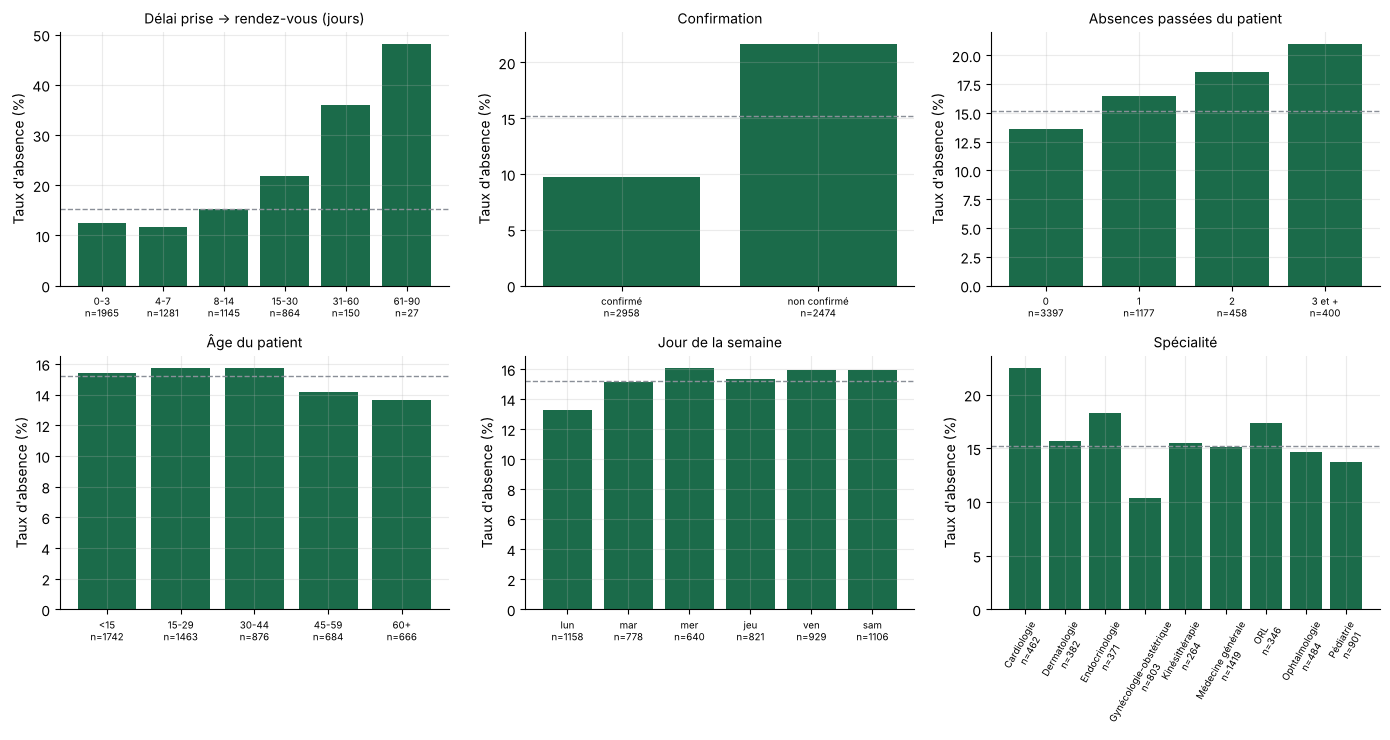

In [3]:
def barres(ax, serie, titre, rotation=0):
    g = clos.groupby(serie, observed=True)["absent"].agg(["mean", "size"])
    ax.bar(range(len(g)), g["mean"] * 100, color=VERT)
    ax.axhline(clos["absent"].mean() * 100, color=GRIS, ls="--", lw=1)
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([f"{i}\nn={n}" for i, n in zip(g.index, g["size"])], rotation=rotation, fontsize=7)
    ax.set_title(titre, fontsize=10); ax.set_ylabel("Taux d'absence (%)")

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
barres(axes[0, 0], pd.cut(clos["delai_jours"], [-1, 3, 7, 14, 30, 60, 91], labels=["0-3", "4-7", "8-14", "15-30", "31-60", "61-90"]), "Délai prise → rendez-vous (jours)")
barres(axes[0, 1], clos["confirme"].map({1.0: "confirmé", 0.0: "non confirmé"}), "Confirmation")
barres(axes[0, 2], pd.cut(clos["nb_absences"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3 et +"]), "Absences passées du patient")
barres(axes[1, 0], pd.cut(clos["age"], [0, 15, 30, 45, 60, 110], labels=["<15", "15-29", "30-44", "45-59", "60+"]), "Âge du patient")
barres(axes[1, 1], pd.Categorical(clos["jour_semaine"].astype(int).map(lambda i: risque.JOURS[i][:3]), categories=[j[:3] for j in risque.JOURS], ordered=True), "Jour de la semaine")
barres(axes[1, 2], clos["specialite"], "Spécialité", rotation=60)
plt.tight_layout(); plt.show()

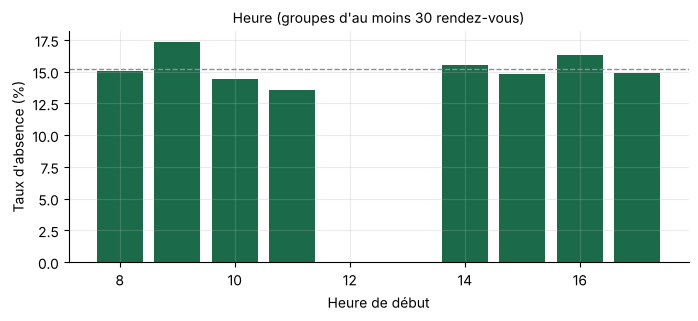

In [4]:
heure = clos.assign(heure_entiere=clos["heure"].astype(int)).groupby("heure_entiere")["absent"].agg(["mean", "size"])
heure = heure[heure["size"] >= 30]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(heure.index, heure["mean"] * 100, color=VERT); ax.axhline(clos["absent"].mean() * 100, color=GRIS, ls="--", lw=1)
ax.set_xlabel("Heure de début"); ax.set_ylabel("Taux d'absence (%)"); ax.set_title("Heure (groupes d'au moins 30 rendez-vous)", fontsize=10)
plt.show()

**Lecture.** Les variables qui séparent le mieux les groupes sont le délai de prise (le risque augmente nettement avec l'attente),
la confirmation et l'historique d'absences du patient. Le jour, l'heure, l'âge et la spécialité ont des effets plus faibles : ils
aident peu, mais le cahier des charges les autorise et ils ne coûtent rien à inclure.

## 3. Choix des variables

| Variable | Utilisée | Remarque |
|---|---|---|
| Délai entre prise et rendez-vous | oui | en jours, et son logarithme (le risque monte vite puis plus lentement) |
| Jour de la semaine, heure | oui | jour en catégories, heure en nombre décimal |
| Spécialité | oui | catégories |
| Âge du patient | oui | à la date du rendez-vous ; âge inconnu ou absurde remplacé par la médiane, avec un indicateur |
| Historique d'absences | oui | nombre d'absences et taux lissé sur les rendez-vous clos **antérieurs** uniquement |
| Confirmation | oui | rendez-vous confirmé ou non |
| Canal de prise, sexe, quartier, médecin | **non** | hors de la liste autorisée par le cahier des charges ; le sexe et le quartier risqueraient en plus de discriminer |

**Éviter la fuite d'information.** L'historique d'un rendez-vous ne regarde jamais le rendez-vous lui-même ni ceux qui le suivent :
c'est vérifié par un test automatique (`tests/test_risque.py`). Sans cela le modèle « verrait » l'issue qu'il doit prédire.

## 4. Découpage temporel

Un tirage au hasard mélangerait passé et futur : le modèle apprendrait sur des rendez-vous postérieurs à ceux qu'il est censé prédire.
On apprend donc sur les **75 % les plus anciens** et on évalue sur les **25 % les plus récents**, comme en production (on note demain avec ce
que l'on sait d'hier).

In [5]:
h = risque.Hypotheses()           # hypothèses de coût par défaut (modifiables par variables d'environnement)
r = risque.apprendre(d, h)
print(f"Apprentissage : {r.nb_apprentissage} rendez-vous clos, taux d'absence {r.taux_absence_apprentissage:.1%}")
print(f"Test          : {r.nb_test} rendez-vous clos à partir du {r.date_coupure:%d/%m/%Y}, taux d'absence {r.taux_absence_test:.1%}")

Apprentissage : 4074 rendez-vous clos, taux d'absence 14.3%
Test          : 1358 rendez-vous clos à partir du 28/07/2026, taux d'absence 17.8%


## 5. Résultats : deux modèles comparés sur la période de test

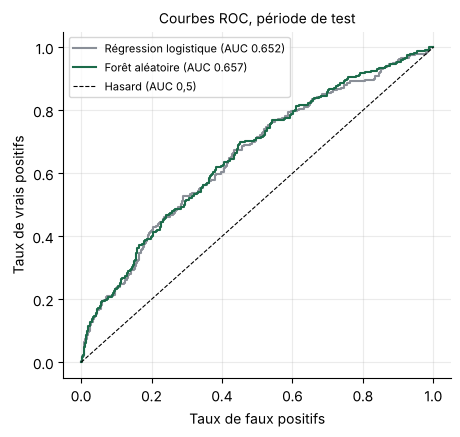

,AUC,Précision moyenne,Score de Brier,Précision (seuil 19.0%),Rappel (seuil 19.0%),Part relancée
Modèle,,,,,,
logistique,0.652,0.307,0.14,0.295,0.450,0.272
foret,0.657,0.305,0.14,0.295,0.421,0.255


In [6]:
clos_tries = clos.sort_values(["debut", "rdv_id"]).reset_index(drop=True)
coupure = int(len(clos_tries) * (1 - risque.PART_TEST))
app, test = clos_tries.iloc[:coupure], clos_tries.iloc[coupure:]
age_med = risque._mediane_age(app)
x_app, x_test = risque._preparer(app, age_med), risque._preparer(test, age_med)
modeles = {n: risque._pipeline(n).fit(x_app, app["absent"]) for n in risque.NOMS_MODELES}
proba = {n: m.predict_proba(x_test)[:, 1] for n, m in modeles.items()}

fig, ax = plt.subplots(figsize=(5, 4.5))
for n, p in proba.items():
    fpr, tpr, _ = roc_curve(test["absent"], p)
    ax.plot(fpr, tpr, label=f"{risque.NOMS_MODELES[n]} (AUC {roc_auc_score(test['absent'], p):.3f})", color=VERT if n == r.retenu else GRIS)
ax.plot([0, 1], [0, 1], ls="--", color="black", lw=0.8, label="Hasard (AUC 0,5)")
ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Taux de vrais positifs"); ax.legend(fontsize=8); ax.set_title("Courbes ROC, période de test", fontsize=10)
plt.show()

pd.DataFrame({
    "Modèle": [e.modele for e in r.modeles.values()],
    "AUC": [round(e.auc, 3) for e in r.modeles.values()],
    "Précision moyenne": [round(e.precision_moyenne, 3) for e in r.modeles.values()],
    "Score de Brier": [round(e.brier, 3) for e in r.modeles.values()],
    f"Précision (seuil {r.seuil:.1%})": [None if e.precision is None else round(e.precision, 3) for e in r.modeles.values()],
    f"Rappel (seuil {r.seuil:.1%})": [None if e.rappel is None else round(e.rappel, 3) for e in r.modeles.values()],
    "Part relancée": [round(e.part_relancee, 3) for e in r.modeles.values()],
}).set_index("Modèle")

**Lecture.** L'AUC mesure la capacité à classer un rendez-vous manqué au-dessus d'un rendez-vous honoré (0,5 = hasard). Les deux modèles font
pratiquement jeu égal : les relations sont simples et la forêt aléatoire n'apporte rien de plus à la régression logistique, qui reste
**explicable**. Le module retient quand même celui dont l'AUC de test est la plus haute et la recalcule chaque nuit ; l'écran de relance
donne les raisons principales à partir du modèle linéaire.

In [7]:
e = r.modeles[r.retenu]
(vn, fp), (fn, vp) = e.matrice
print(f"Modèle retenu : {risque.NOMS_MODELES[r.retenu]}  |  seuil {r.seuil:.1%}")
pd.DataFrame([[vn, fp], [fn, vp]], index=["Réalité : venu", "Réalité : absent"], columns=["Non relancé", "Relancé"])

Modèle retenu : Forêt aléatoire  |  seuil 19.0%


,Non relancé,Relancé
Réalité : venu,872,244
Réalité : absent,140,102


**Calibration.** Pour utiliser le score comme probabilité (donc pour appliquer le seuil du coût/bénéfice), le risque prédit doit être proche
du taux observé. On compare par tranche de score.

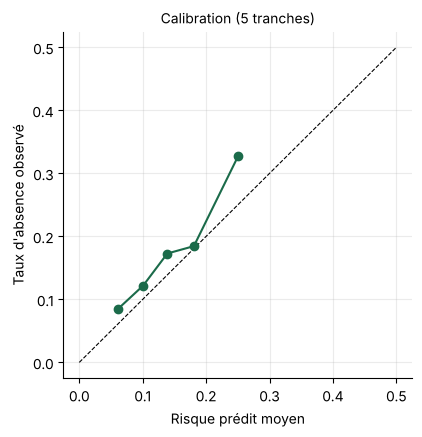

,prevu,observe,effectif
tranche,,,
"(0.0349, 0.0779]",0.061,0.085,272
"(0.0779, 0.12]",0.101,0.122,271
"(0.12, 0.158]",0.139,0.173,272
"(0.158, 0.204]",0.181,0.185,271
"(0.204, 0.384]",0.250,0.327,272


In [8]:
p = proba[r.retenu]
cal = pd.DataFrame({"p": p, "y": test["absent"].to_numpy()})
cal["tranche"] = pd.qcut(cal["p"], 5, duplicates="drop")
cal = cal.groupby("tranche", observed=True).agg(prevu=("p", "mean"), observe=("y", "mean"), effectif=("y", "size"))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 0.5], [0, 0.5], ls="--", color="black", lw=0.8); ax.plot(cal["prevu"], cal["observe"], "o-", color=VERT)
ax.set_xlabel("Risque prédit moyen"); ax.set_ylabel("Taux d'absence observé"); ax.set_title("Calibration (5 tranches)", fontsize=10)
plt.show()
cal.round(3)

**Lecture de la calibration.** Le risque est un peu sous-estimé sur la période de test : son taux d'absence est plus élevé que celui de
l'apprentissage (une petite dérive, voir les limites). Le classement des rendez-vous reste bon, c'est le niveau absolu qui est légèrement bas ;
le modèle définitif, réajusté chaque nuit sur toutes les données récentes, corrige une partie de cet écart.

## 6. Le seuil : coût d'un appel contre coût d'un créneau perdu

Relancer un patient dont le risque est `p` coûte un appel et rapporte, en moyenne, `p × efficacité × coût du créneau`.
L'appel est rentable lorsque

> `p ≥ coût de l'appel / (efficacité de la relance × coût d'un créneau perdu)`

Les trois montants ne sont **pas dans les données** : ce sont des hypothèses à faire valider par la clinique
(par défaut 1 000 FCFA l'appel, 15 000 FCFA le créneau, 35 % d'absences évitées par une relance).

Seuil théorique = 1000 / (0.35 x 15000) = 19.0%


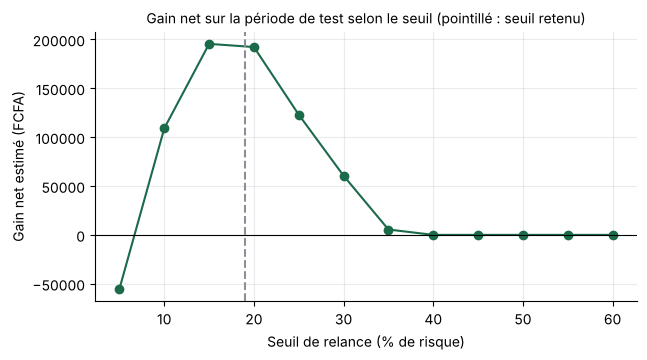

,Gain net estimé (FCFA)
ne_relancer_personne,0.0
relancer_tout_le_monde,-87500.0
relancer_selon_le_score,189500.0


In [9]:
print(f"Seuil théorique = {h.cout_relance:.0f} / ({h.efficacite} x {h.cout_creneau:.0f}) = {r.seuil:.1%}")
c = pd.DataFrame(r.courbe_seuils)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(c["seuil"] * 100, c["gain_net"], "o-", color=VERT); ax.axvline(r.seuil * 100, ls="--", color=GRIS)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Seuil de relance (% de risque)"); ax.set_ylabel("Gain net estimé (FCFA)")
ax.set_title("Gain net sur la période de test selon le seuil (pointillé : seuil retenu)", fontsize=10)
plt.show()
pd.Series(r.strategies, name="Gain net estimé (FCFA)").round(0).to_frame()

**Lecture.** Le gain est maximal au voisinage du seuil théorique, ce qui conforte le raisonnement. Relancer tout le monde coûte plus
que cela ne rapporte (taux d'absence faible) ; relancer selon le score est la seule stratégie nettement positive. Plus le seuil
monte, moins on relance, mais on manque une partie des absences : le rappel baisse.

## 7. Ce que le modèle a appris (régression logistique, variables standardisées)

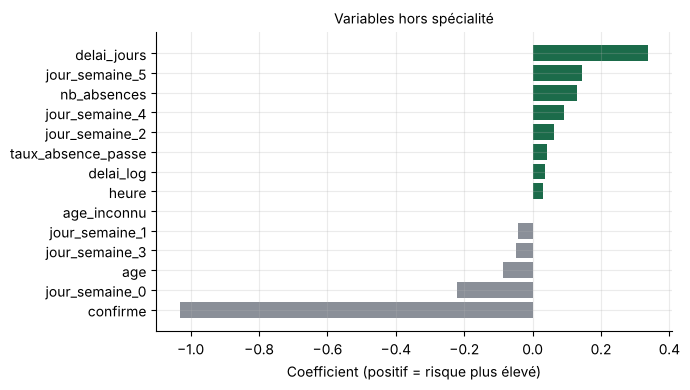

In [10]:
lin = modeles["logistique"]
noms = [n.split("__", 1)[1] for n in lin.named_steps["transformation"].get_feature_names_out()]
coef = pd.Series(lin.named_steps["modele"].coef_[0], index=noms).sort_values()
coef = coef[~coef.index.str.startswith("specialite_")]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(coef.index, coef.values, color=[VERT if v > 0 else GRIS for v in coef.values])
ax.set_xlabel("Coefficient (positif = risque plus élevé)"); ax.set_title("Variables hors spécialité", fontsize=10)
plt.tight_layout(); plt.show()

## 8. Limites

1. **Données synthétiques.** Les absences ont été générées à partir de quelques facteurs connus ; le modèle retrouve une partie de ces
   facteurs, ce qui valide la chaîne technique, **pas** la valeur prédictive sur de vrais patients. L'AUC réelle serait différente.
2. **Biais possibles.** Un patient sans historique est mal éclairé par le modèle ; un patient jeune ou âgé n'a pas les mêmes raisons
   de manquer. Le modèle ignore les causes personnelles (transport, maladie, travail). Il est volontairement privé du sexe, du quartier
   et du canal. Une relance ne doit jamais devenir un traitement différent du patient (refus, pénalité) : le score ne bloque aucune prise.
3. **Dérive dans le temps.** Le comportement des patients change. Le module nocturne réapprend chaque nuit et enregistre l'AUC de chaque
   exécution (table `evaluations_risque`) : une baisse durable signale une dérive. La vérification ci-dessous la regarde mois par mois.
4. **Historique court.** Au début de la période, personne n'a d'historique ; avec un an de données seulement, la variable
   « absences passées » reste peu informative.
5. **Effet de la relance non mesuré.** Le gain net suppose que la relance évite 35 % des absences ; seule une expérience (relancer un
   échantillon, pas l'autre) permettrait de le mesurer.
6. **Faible puissance.** Une AUC proche de 0,65 classe moyennement : le score aide à prioriser, il ne désigne pas avec certitude.

In [11]:
# Stabilité dans le temps : AUC du modèle appris sur la période d'apprentissage, mois par mois sur la période de test.
test_m = test.assign(mois=test["debut"].dt.to_period("M"), p=proba[r.retenu])
lignes = []
for mois, g in test_m.groupby("mois"):
    if g["absent"].nunique() == 2 and len(g) >= 50:
        lignes.append({"Mois": str(mois), "Rendez-vous": len(g), "Taux d'absence": round(g["absent"].mean(), 3), "AUC": round(roc_auc_score(g["absent"], g["p"]), 3)})
pd.DataFrame(lignes).set_index("Mois")

,Rendez-vous,Taux d'absence,AUC
Mois,,,
2026-07,85,0.141,0.729
2026-08,565,0.182,0.628
2026-09,547,0.172,0.663
2026-10,161,0.205,0.697


## 9. Conclusion

- Le score classe les rendez-vous mieux que le hasard, sans fuite d'information, avec une validation dans le temps.
- Le seuil de relance vient d'un calcul de coût/bénéfice explicite, dont les hypothèses sont visibles et modifiables
  (`MEDIRDV_COUT_RELANCE`, `MEDIRDV_COUT_CRENEAU`, `MEDIRDV_EFFICACITE_RELANCE`).
- La liste des rendez-vous à relancer est triée par risque, avec les raisons principales ; elle est réservée aux agents d'accueil et au
  responsable, jamais visible du patient, et n'intervient dans aucune règle de prise de rendez-vous.
- Avant un usage réel : recalibrer sur les vraies données de la clinique, valider les coûts, et mesurer l'effet réel des relances.